In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = 'GPU-fbdc2a7b-c9f5-5e02-17f9-4e00342e866c'
import importlib
import helpers
from tangermeme.predict import predict
from tangermeme.utils import characters
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.model_selection import train_test_split
importlib.reload(helpers)

import helpers

In [2]:
motif_dict = helpers.make_motif_dict(100, 10)
#motif_dict

In [ ]:
seq, labels = helpers.generate_dataset(motif_dict, 25_000, sequence_length=2000, num_tasks=50)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 25000/25000 [01:24<00:00, 294.18it/s]


In [38]:
train_loader, val_loader, test_loader = helpers.create_dataloaders(seq, labels, batch_size = 32 * 8)

In [ ]:
model, train_losses, val_losses = helpers.train_simple_model(train_loader, val_loader, num_tasks=50,num_epochs=200, lr=1e-4, device='cuda')

In [40]:
model

MotifEffectSum(
  (conv1): Conv1d(4, 320, kernel_size=(8,), stride=(1,), padding=same, bias=False)
  (conv2): Conv1d(320, 480, kernel_size=(8,), stride=(1,), padding=same, bias=False)
  (conv3): Conv1d(480, 960, kernel_size=(8,), stride=(1,), padding=same, bias=False)
  (act): ReLU()
  (to_tasks): Conv1d(960, 50, kernel_size=(1,), stride=(1,), bias=False)
)

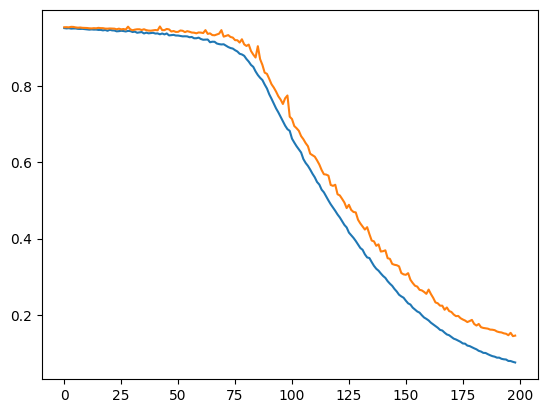

In [50]:
import matplotlib.pyplot as plt
plt.plot(train_losses[1:])
plt.plot(val_losses[1:])
plt.show()

In [48]:
import pickle

# save model and architecure
torch.save(model, "model_trained.pth")

# save motif dict
with open('motif_dict_trained.pkl', 'wb') as f:
    pickle.dump(motif_dict, f)


In [42]:
from tqdm.auto import tqdm

motif_feature_leakage = {}
model.eval()

for m in tqdm(motif_dict.keys()):
    actual_effect = motif_dict[m]['effect']
    sparsity_array = motif_dict[m]['sparsity']
    leakage = helpers.measure_feature_leakage(m, model, sparsity_array, actual_effect)

    motif_feature_leakage[m] = leakage

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:16<00:00,  6.02it/s]


In [43]:
leakage

{'actual_effect_size': 0.29959658420502316,
 'proportion_tasks_active': 0.46,
 'leakage_effect': 0.00787741132080555,
 'predicted_effect': np.float32(0.045365285),
 'statistic': 77.0,
 'p_value': 0.005940347909927368}

In [44]:
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import pearsonr

# motif_feature_leakage is your dict
df = pd.DataFrame.from_dict(motif_feature_leakage, orient='index')
df = df[['leakage_effect', 'actual_effect_size', 'proportion_tasks_active','predicted_effect']].astype(float)
# df['leakage_effect'] = df['leakage_effect'].abs()

# Linear model with interaction term
m = smf.ols('leakage_effect ~ actual_effect_size * proportion_tasks_active', data=df).fit()
print(f"R^2 = {m.rsquared:.4f}")

R^2 = 0.6027


In [45]:
pearsonr(df['actual_effect_size'], df['predicted_effect'])

PearsonRResult(statistic=np.float64(0.8947436480440827), pvalue=np.float64(4.3912184434705255e-36))

In [46]:
pearsonr(df['actual_effect_size'], df['leakage_effect'])

PearsonRResult(statistic=np.float64(-0.6038547426401735), pvalue=np.float64(2.9172435488197666e-11))

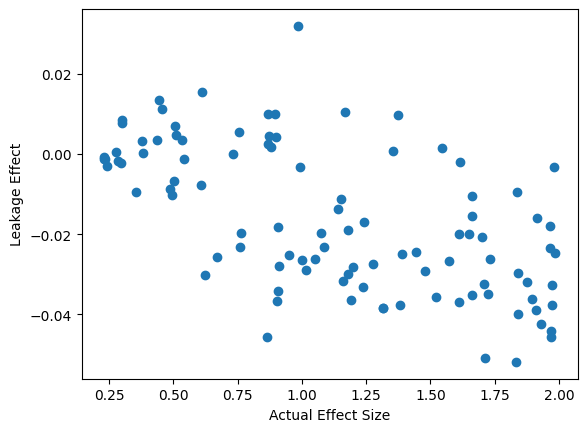

In [47]:
import matplotlib.pyplot as plt
import pandas as pd
plt.scatter(df['actual_effect_size'], df['leakage_effect'])
plt.xlabel('Actual Effect Size')
plt.ylabel('Leakage Effect')
plt.show()

Correlation: r = -0.6039, p = 2.92e-11


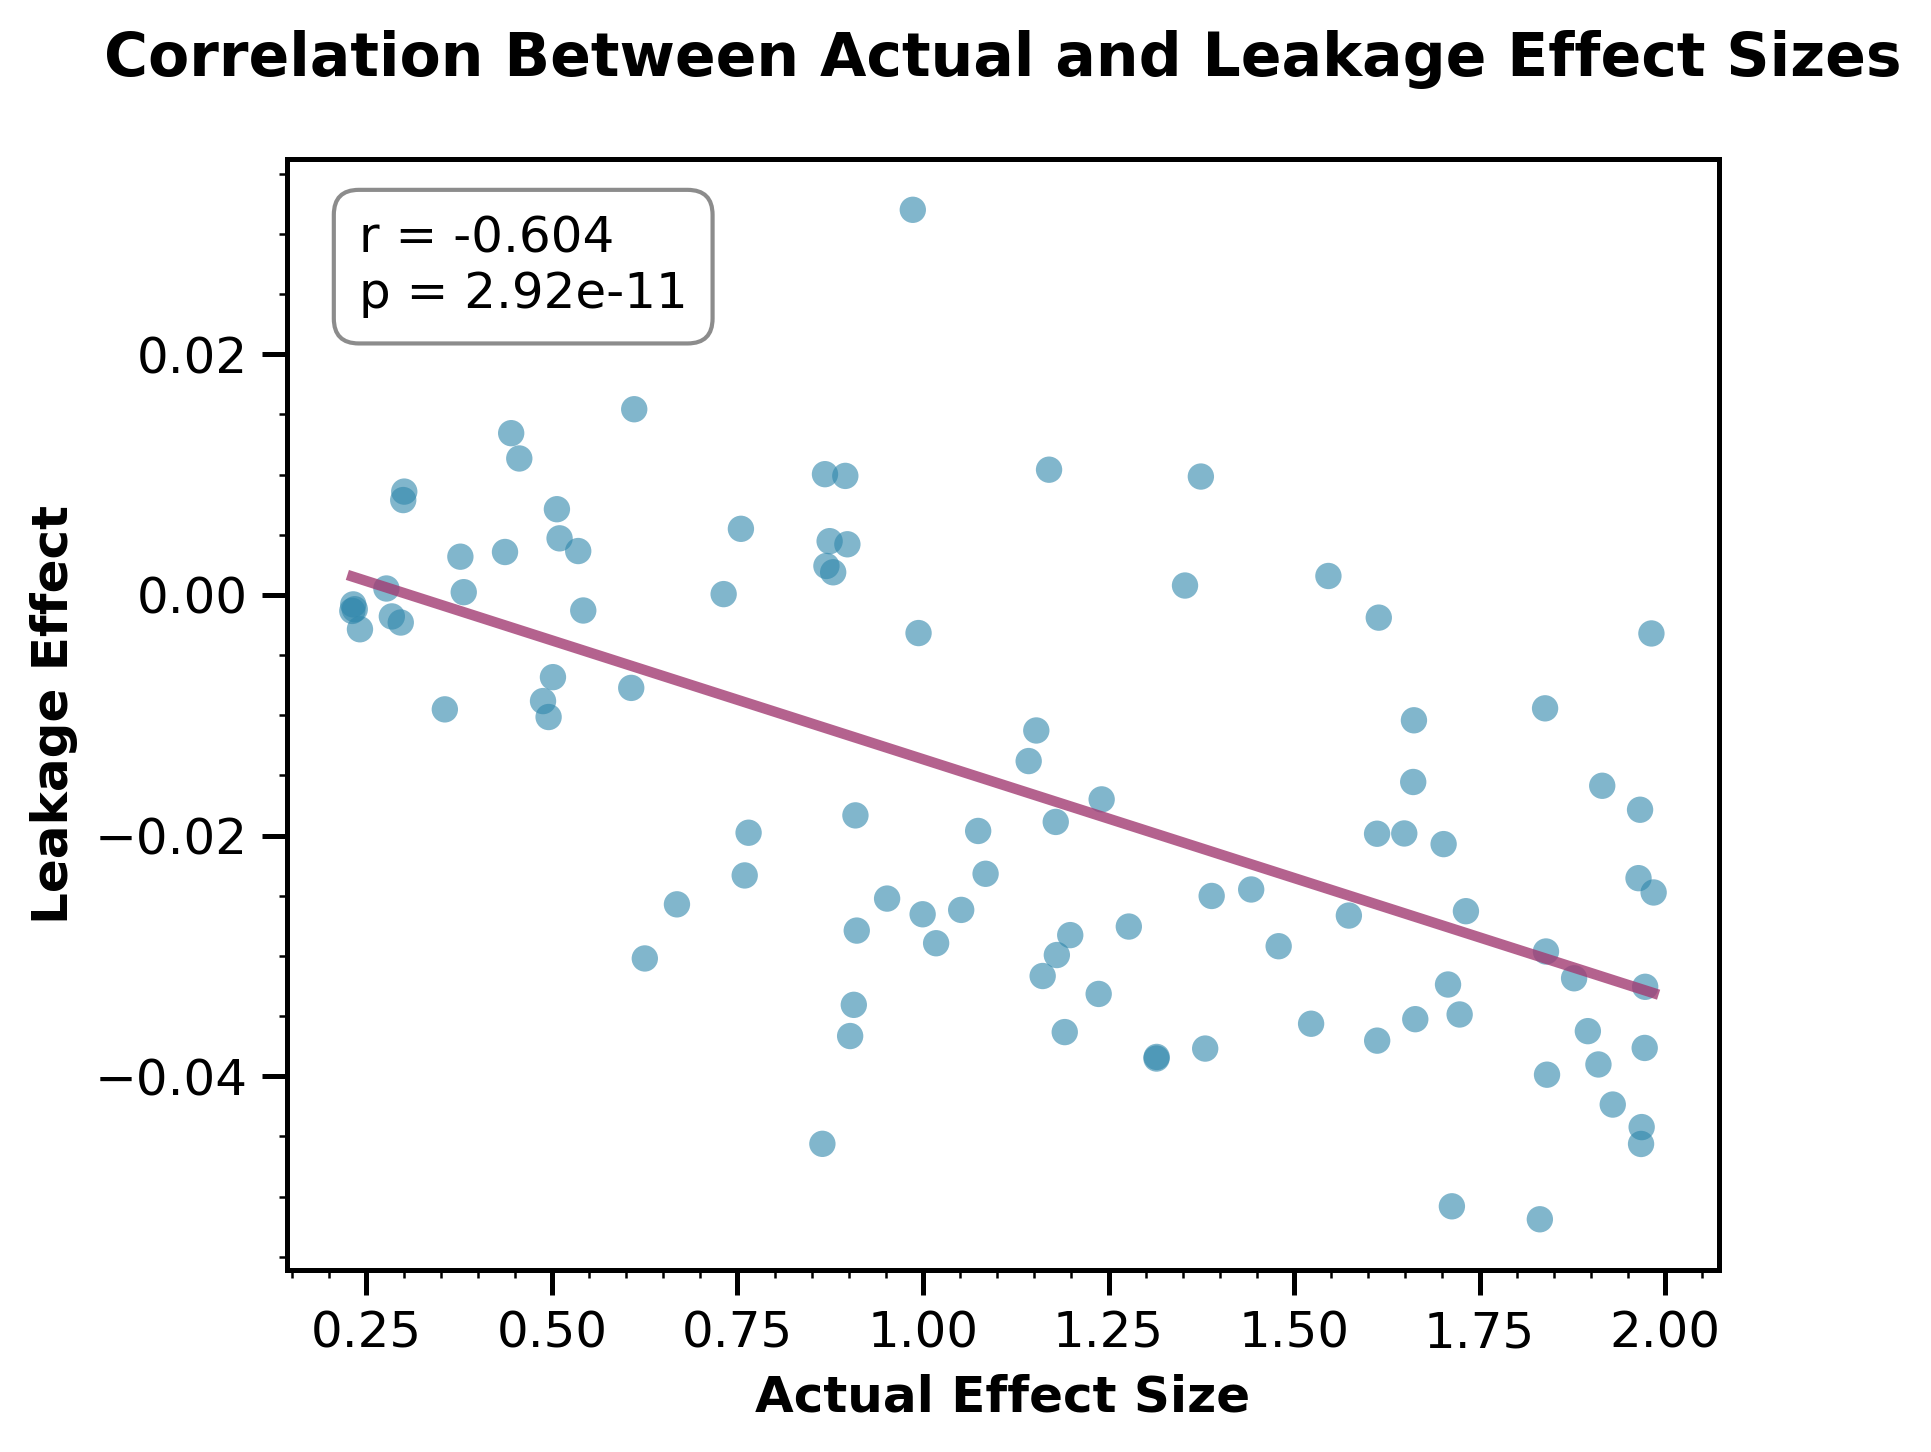

In [53]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
import matplotlib

# Set matplotlib for publication quality with DejaVu Sans font
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.2
plt.rcParams['ytick.major.width'] = 1.2
plt.rcParams['pdf.fonttype'] = 42  # Ensures text is editable in Illustrator
plt.rcParams['ps.fonttype'] = 42   # Ensures text is editable in Illustrator

# Extract your data
x_data = df['actual_effect_size'].values
y_data = df['leakage_effect'].values

# Remove any NaN values
mask = ~(np.isnan(x_data) | np.isnan(y_data))
x_data = x_data[mask]
y_data = y_data[mask]

# Calculate correlation
r_value, p_value = pearsonr(x_data, y_data)

# Fit linear regression for trend line
reg = LinearRegression()
X_reshaped = x_data.reshape(-1, 1)
reg.fit(X_reshaped, y_data)

# Generate trend line points
x_trend = np.linspace(x_data.min(), x_data.max(), 100)
y_trend = reg.predict(x_trend.reshape(-1, 1))

# Create the figure
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

# Create scatter plot
scatter = ax.scatter(x_data, y_data, 
                    alpha=0.6, 
                    s=40,
                    c='#2E86AB',
                    edgecolors='none')

# Add trend line
ax.plot(x_trend, y_trend, 
        color='#A23B72',
        linewidth=2.5,
        alpha=0.8)

# Add correlation text
ax.text(0.05, 0.95, 
        f'r = {r_value:.3f}\np = {p_value:.2e}',
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5', 
                 facecolor='white', 
                 edgecolor='gray',
                 alpha=0.9))

# Customize axes
ax.set_xlabel('Actual Effect Size', fontweight='bold')
ax.set_ylabel('Leakage Effect', fontweight='bold')
ax.set_title('Correlation Between Actual and Leakage Effect Sizes', fontweight='bold', pad=20)

# NO GRID (as requested)
ax.grid(False)

# Customize spines
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')

# Set tick parameters
ax.tick_params(direction='out', length=6, width=1.2, colors='black', which='major')
ax.minorticks_on()

# Tight layout
plt.tight_layout()

# Save as PDF with vector fonts for Adobe Illustrator compatibility
plt.savefig('leakage_effect_size_correlation.pdf', 
            format='pdf',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Also save as SVG for additional vector format option
plt.savefig('leakage_effect_size_correlation.svg',
            format='svg',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

print(f"Correlation: r = {r_value:.4f}, p = {p_value:.2e}")
plt.show()

Correlation: r = 0.8947, p = 4.39e-36


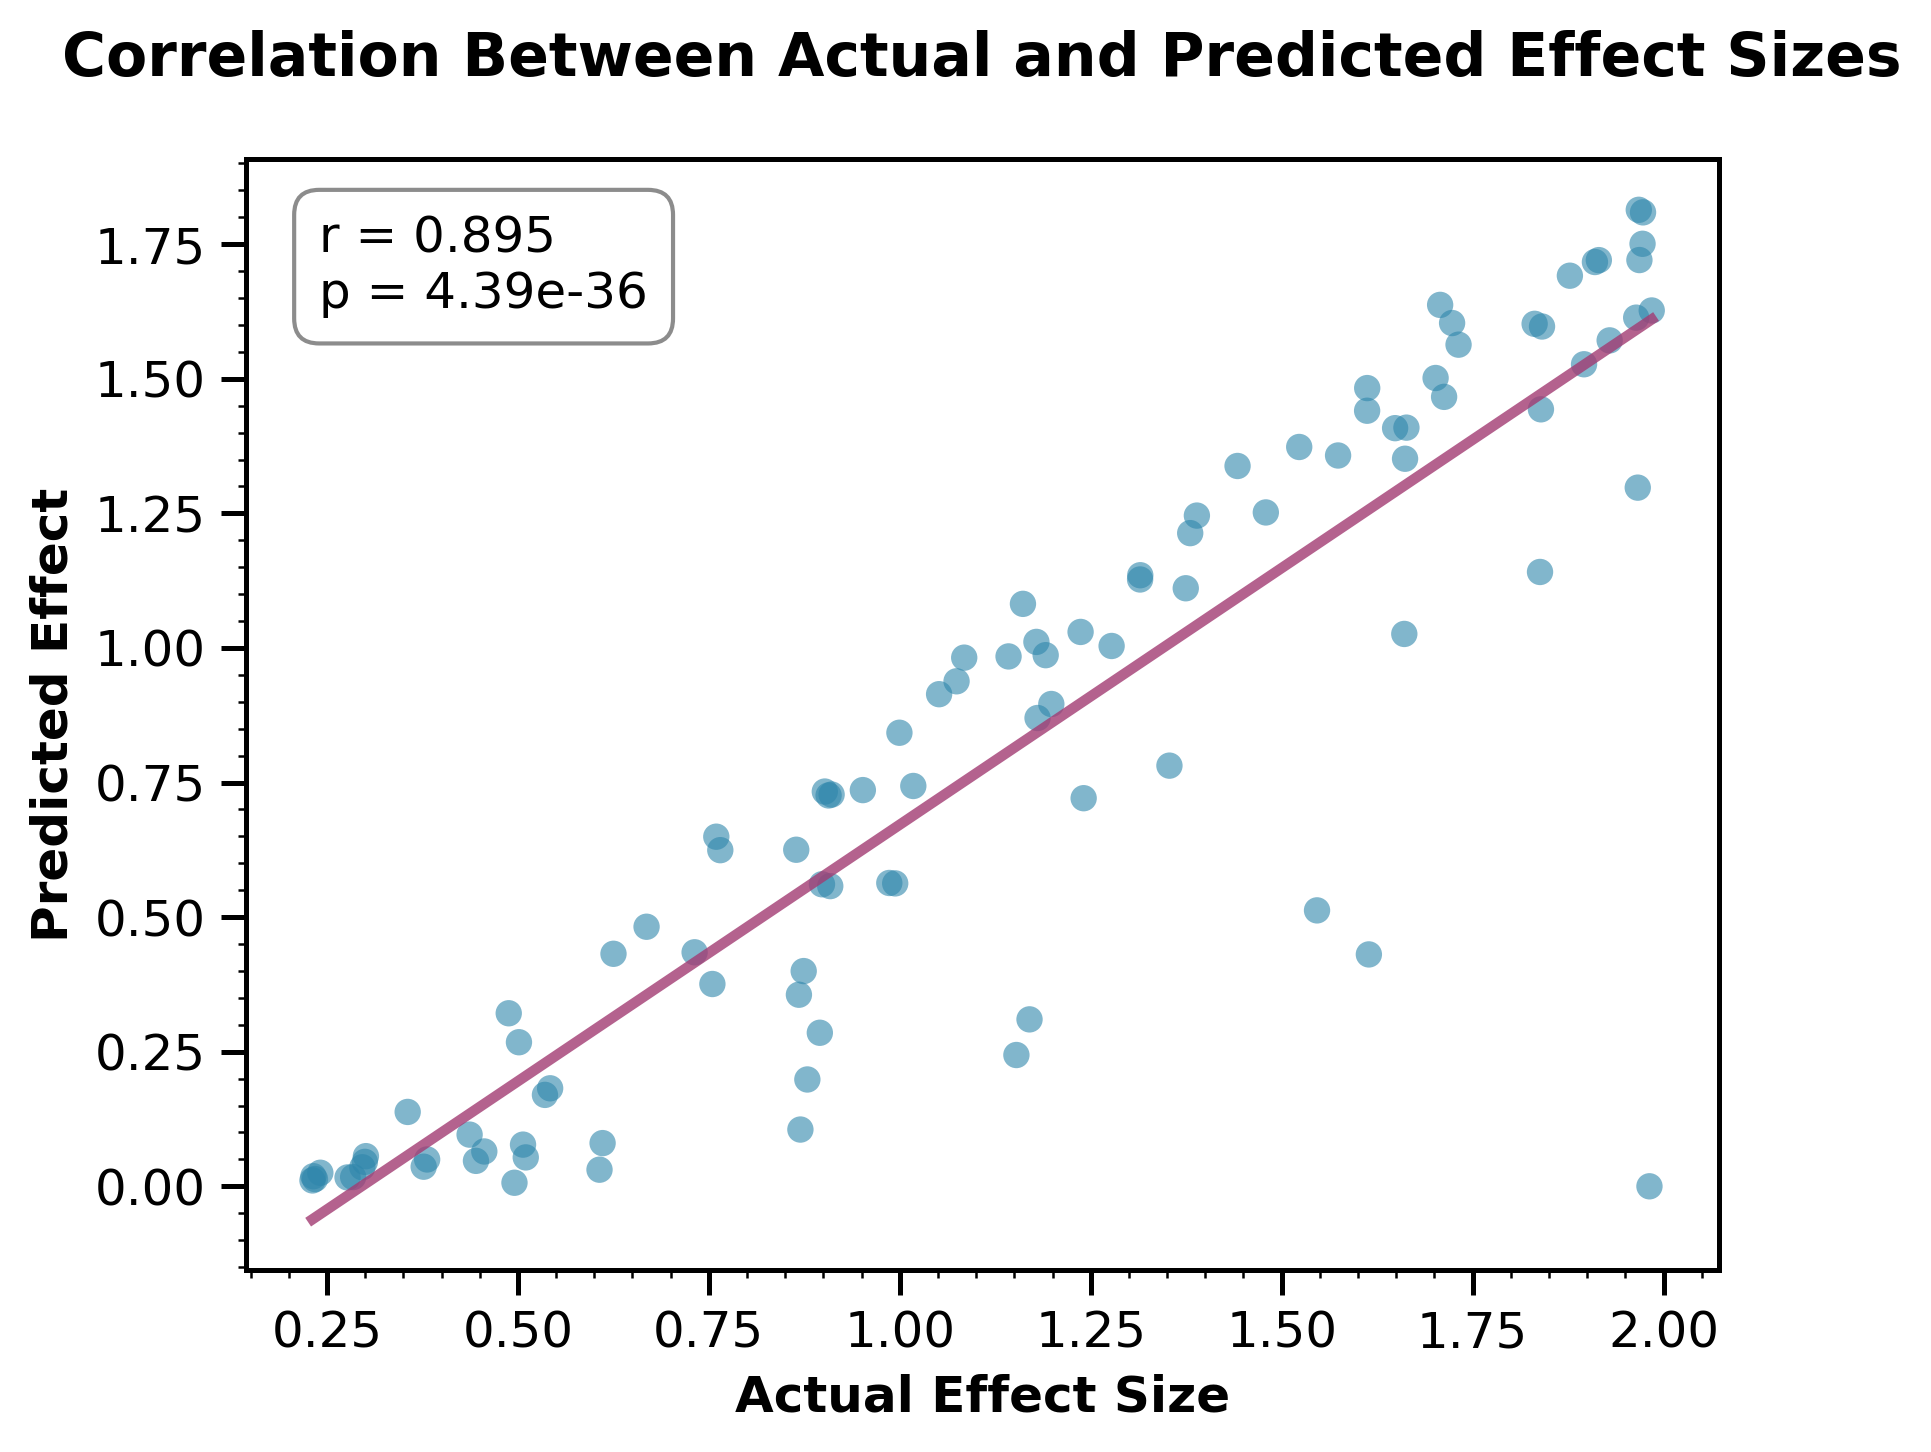

In [54]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
import matplotlib

# Set matplotlib for publication quality with DejaVu Sans font
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.2
plt.rcParams['ytick.major.width'] = 1.2
plt.rcParams['pdf.fonttype'] = 42  # Ensures text is editable in Illustrator
plt.rcParams['ps.fonttype'] = 42   # Ensures text is editable in Illustrator

# Extract your data
x_data = df['actual_effect_size'].values
y_data = df['predicted_effect'].values

# Remove any NaN values
mask = ~(np.isnan(x_data) | np.isnan(y_data))
x_data = x_data[mask]
y_data = y_data[mask]

# Calculate correlation
r_value, p_value = pearsonr(x_data, y_data)

# Fit linear regression for trend line
reg = LinearRegression()
X_reshaped = x_data.reshape(-1, 1)
reg.fit(X_reshaped, y_data)

# Generate trend line points
x_trend = np.linspace(x_data.min(), x_data.max(), 100)
y_trend = reg.predict(x_trend.reshape(-1, 1))

# Create the figure
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

# Create scatter plot
scatter = ax.scatter(x_data, y_data, 
                    alpha=0.6, 
                    s=40,
                    c='#2E86AB',
                    edgecolors='none')

# Add trend line
ax.plot(x_trend, y_trend, 
        color='#A23B72',
        linewidth=2.5,
        alpha=0.8)

# Add correlation text
ax.text(0.05, 0.95, 
        f'r = {r_value:.3f}\np = {p_value:.2e}',
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5', 
                 facecolor='white', 
                 edgecolor='gray',
                 alpha=0.9))

# Customize axes
ax.set_xlabel('Actual Effect Size', fontweight='bold')
ax.set_ylabel('Predicted Effect', fontweight='bold')
ax.set_title('Correlation Between Actual and Predicted Effect Sizes', fontweight='bold', pad=20)

# NO GRID (as requested)
ax.grid(False)

# Customize spines
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')

# Set tick parameters
ax.tick_params(direction='out', length=6, width=1.2, colors='black', which='major')
ax.minorticks_on()

# Tight layout
plt.tight_layout()

# Save as PDF with vector fonts for Adobe Illustrator compatibility
plt.savefig('effect_size_correlation.pdf', 
            format='pdf',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Also save as SVG for additional vector format option
plt.savefig('effect_size_correlation.svg',
            format='svg',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

print(f"Correlation: r = {r_value:.4f}, p = {p_value:.2e}")
plt.show()